# Applied Statistics Assessment Notebook


## Introduction  

This notebook explores the Iris dataset using statistical methods and data visualisation in Python.  

The objective is to investigate the distribution of petal lengths,examine the relationship between petal length and petal width,and determine whether statistically significant differences existbetween the three Iris species: Setosa, Versicolor and Virginica.  

The assessment is divided into four problems:  

* Problem 1 Exploring petal length distributions and assessing the suitability of a normal distribution.  
* Problem 2 Investigating the correlation between petal length and petal width.  
* Problem 3 Comparing species using independent-samples t-tests.  
* Problem 4 Comparing species using one-way analysis of variance (ANOVA).  

The analysis is carried out using Python libraries including Pandas, NumPy, Matplotlib and SciPy.  

Each problem includes statistical calculations, interpretation of the results and relevant visualisations where appropriate.  

## Problem 1: Exploring Petal Length  
The Iris dataset contains measurements of 150 iris flowers belonging to three species: setosa, versicolor, and virginica, for each flower, the dataset records sepal length, sepal width, petal length, and petal width.

This problem investigates the distribution of petal lengths across the complete dataset and within each species.  

The analysis involves:  

- Plotting a histogram of petal lengths for all 150 flowers.  

- Superimposing a normal distribution curve using the calculated mean and standard deviation.  

- Creating separate histograms and normal distribution curves for each species.  

- Reporting the mean and standard deviation for the complete dataset and each species.  

- Comparing the distributions and discussing whether a normal distribution is a reasonable model. 

In [1]:
# Import Pandas library for data manipulation and analysis 
import pandas as pd

# Import matplotlib for creating data visualizations
import matplotlib.pyplot as plt

# Import numpy for numerical operations
import numpy as np

# Import scipy.stats for statistical functions and tests
from scipy import stats


### Histogram of Iris Petal Lengths (All 150 Flowers)  

A histogram is used to visualise the distribution of petal lengths across all 150 Iris flowers.

The x-axis represents petal length in centimetres, while the y-axis shows the number of flowers within each interval  

In [2]:
# Pandas documentation for loading external files                                
# https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html

# load Iris dataset from the Web URL
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

# read URL data directly into a DataFrame
df = pd.read_csv(url)

# view columns and data head
print(df.head())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [3]:
# get petal length data
petal_length = df['petal_length']

# view petal length column and data head
print(petal_length.head())


0    1.4
1    1.4
2    1.3
3    1.5
4    1.4
Name: petal_length, dtype: float64


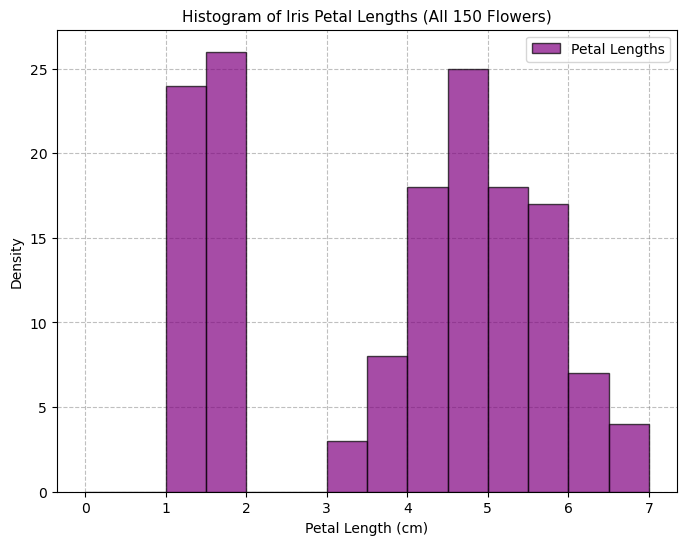

In [ ]:
# plot documentation:
# https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html


# plot a histogram showing the petal lengths of all 150 flowers
plt.figure(figsize=(8, 6))
plt.hist(petal_length, bins= np.linspace(0, 7, 15), color='purple', edgecolor='black', alpha=0.7, zorder=3)

# label the axes and add a title
plt.title('Histogram of Iris Petal Lengths (All 150 Flowers)', fontsize=11)
plt.xlabel('Petal Length (cm)', fontsize=10)
plt.ylabel('Density', fontsize=10)

# add a grid to the plot for better readability
plt.grid(True, color='gray', linestyle='--', alpha=0.5)
plt.legend(['Petal Lengths'], loc='upper right')

# display the plot
plt.show()


### Normal Distribution Superimposed on Iris Petal Length Histogram (All 150 Flowers)

Normal distribution: A curve that tends to occur when most values are close to the mean (average), with fewer values further away from it.  
It creates a symmetrical, bell-shaped curve that peaks around the mean and gradually decreases towards both ends.  

The normal distribution is calculated using the mean (μ) and standard deviation (σ) of the petal lengths. These two statistical measures are calculated using the following formulas: 

* Mean (μ):  
The average petal length, calculated by adding all petal lengths and dividing by the total number of flowers.

$$
\mu = \frac{\sum_{i=1}^{n} x_i}{n}
$$

In Python: np.mean(petal_length)

<br>  
<br>  

* Standard deviation (σ):  
Measures how spread out the petal lengths are around the mean. A smaller standard deviation indicates values closer to the mean, while a larger standard deviation indicates greater variation.

$$
\sigma = \sqrt{\frac{\sum_{i=1}^{n}(x_i-\mu)^2}{n}}
$$

In Python: np.std(petal_length)

<br>  
<br>  


* Normal distribution (PDF):  
Uses the mean and standard deviation to calculate the theoretical bell-shaped curve.

$$
f(x) = \frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{(x-\mu)^2}{2\sigma^2}}
$$

In Python: stats.norm.pdf(x, mean, std)
<br>  
<br>  


Where:

x: Individual petal length value (cm).

μ: Mean petal length.

σ: Standard deviation.

n: Total number of flowers (150).

Σ: Summation symbol (add all values).

π: (Pi ≈ 3.14) A constant that helps calculate the normal curve.

e: (Euler’s number ≈ 2.72): A constant that helps create the bell shape.


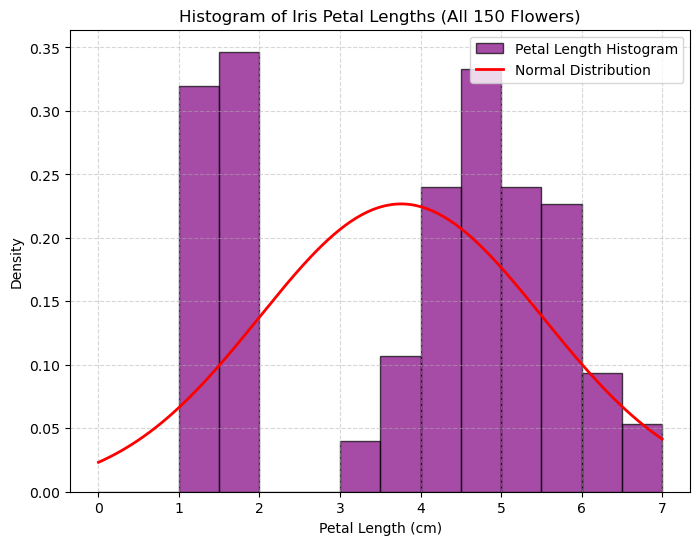

In [ ]:
# SciPy documentation for the normal probability density function (PDF)     
# https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html

# NumPy documentation for calculating the mean
# https://numpy.org/doc/stable/reference/generated/numpy.mean.html

# NumPy documentation for calculating the standard deviation
# https://numpy.org/doc/stable/reference/generated/numpy.std.html


# calculate mean and standard deviation
mean = np.mean(petal_length)
std = np.std(petal_length)

# create histogram
# store the figure in a variable for later comparison
fig_all = plt.figure(figsize=(8, 6))

plt.hist(petal_length, bins=np.linspace(0, 7, 15), color='purple', edgecolor='black', alpha=0.7, density=True, label='Petal Length Histogram')

# superimpose normal distribution using stats.norm
x = np.linspace(0, 7, 200)
plt.plot(x, stats.norm.pdf(x, mean, std),
         color='red', linewidth=2, label='Normal Distribution')

# add labels and title
plt.title('Histogram of Iris Petal Lengths (All 150 Flowers)')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.5)

plt.legend()
plt.show()


### Petal Length Distributions by Species  

The dataset is filtered into three species: Setosa, Versicolor and Virginica.

Separate histograms are created to examine how petal lengths vary within each species.

In [6]:
# pandas documentation for filtering data : The unique() method returns the unique values in a Series.
# https://pandas.pydata.org/docs/reference/api/pandas.Series.unique.html 


# find how many species are in the dataset from the species column of the DataFrame
species = df['species'].unique()

# show species
print(species)


['setosa' 'versicolor' 'virginica']


In [7]:
# pandas documentation for counting values in a Series
# https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html


# check the number of flowers for each species
print(df['species'].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [17]:
# filter the dataset by species to get petal lengths for each species
setosa_petal_length = df[df['species'] == 'setosa']['petal_length']
versicolor_petal_length = df[df['species'] == 'versicolor']['petal_length']
virginica_petal_length = df[df['species'] == 'virginica']['petal_length']


# verify the extracted petal lengths for each species
print("Setosa:")
print(setosa_petal_length.head())

print("\nVersicolor:")
print(versicolor_petal_length.head())

print("\nVirginica:")
print(virginica_petal_length.head())

Setosa:
0    1.4
1    1.4
2    1.3
3    1.5
4    1.4
Name: petal_length, dtype: float64

Versicolor:
50    4.7
51    4.5
52    4.9
53    4.0
54    4.6
Name: petal_length, dtype: float64

Virginica:
100    6.0
101    5.1
102    5.9
103    5.6
104    5.8
Name: petal_length, dtype: float64


#### Histogram and Normal Distribution of Setosa Petal Length



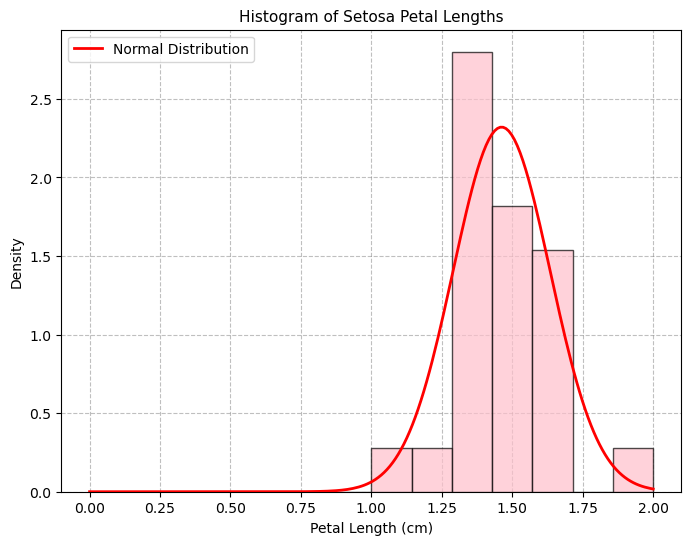

In [ ]:
# calculate mean and standard deviation for Setosa
mean = np.mean(setosa_petal_length)
std = np.std(setosa_petal_length)

# plot a histogram showing the petal lengths of Setosa flowers
# use density=True to scale the histogram for comparison with the normal distribution curve
# store the figure in a variable for later comparison
fig_setosa = plt.figure(figsize=(8, 6))
plt.hist(setosa_petal_length, bins= np.linspace(0, 2, 15), alpha=0.7, color='pink', edgecolor='black', zorder=3, density=True)

# surimpose normal distribution curve
x = np.linspace(0, 2, 200)
plt.plot(x, stats.norm.pdf(x, mean, std),color='red', linewidth=2, zorder=4, label='Normal Distribution')

# label the axes and add a title
plt.title('Histogram of Setosa Petal Lengths', fontsize=11)
plt.xlabel('Petal Length (cm)', fontsize=10)
plt.ylabel('Density', fontsize=10)

# Add a grid to the plot for better readability
plt.grid(True, color='gray', linestyle='--', alpha=0.5)
plt.legend()


# display the plot
plt.show()


#### Histogram and Normal Distribution of Versicolor Petal Lengths

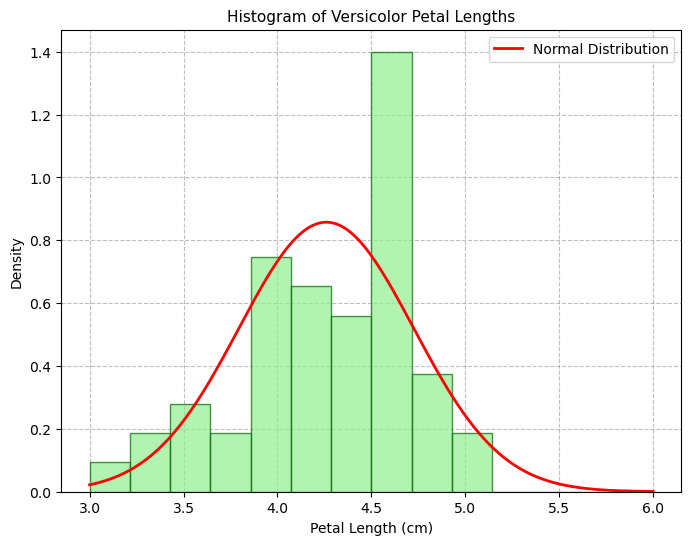

In [10]:
# calculate mean and standard deviation for Versicolor
mean = np.mean(versicolor_petal_length)
std = np.std(versicolor_petal_length)

# plot a histogram showing the petal lengths of Versicolor flowers
# Use density=True to scale the histogram for comparison with the normal distribution curve
# store the figure in a variable for later comparison
fig_versicolor = plt.figure(figsize=(8, 6))
plt.hist(versicolor_petal_length, bins=np.linspace(3, 6, 15), alpha=0.7, color='lightgreen', edgecolor='darkgreen', zorder=3, density=True)


# surimpose normal distribution curve
x = np.linspace(3, 6, 200)
plt.plot(x, stats.norm.pdf(x, mean, std), color='red', linewidth=2, zorder=4, label='Normal Distribution')

# label the axes and add a title
plt.title('Histogram of Versicolor Petal Lengths', fontsize=11)
plt.xlabel('Petal Length (cm)', fontsize=10)
plt.ylabel('Density', fontsize=10)

# Add a grid to the plot for better readability
plt.grid(True, color='gray', linestyle='--', alpha=0.5)
plt.legend()

# Display the plot
plt.show()


#### Histogram and Normal Distribution of Virginica Petal Lengths

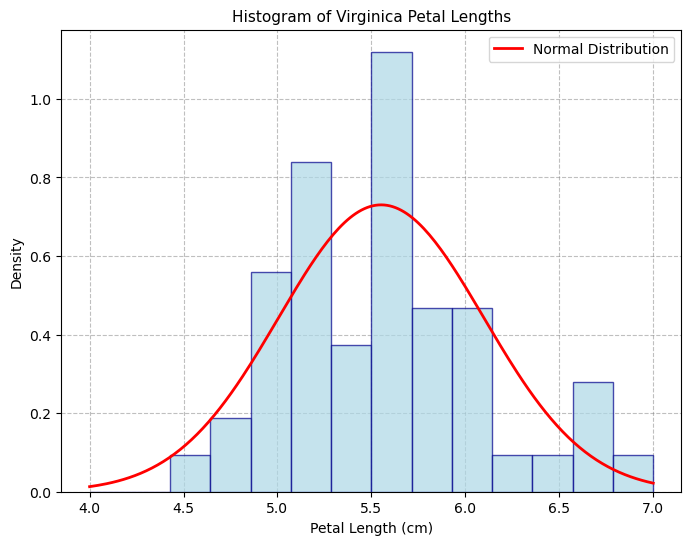

In [11]:
# calculate mean and standard deviation for Virginica
mean = np.mean(virginica_petal_length)
std = np.std(virginica_petal_length)

# plot a histogram showing the petal lengths of Virginica flowers
# use density=True to scale the histogram for comparison with the normal distribution curve
# store the figure in a variable for later comparison
fig_virginica = plt.figure(figsize=(8, 6))
plt.hist(virginica_petal_length, bins=np.linspace(4, 7, 15), alpha=0.7, color='lightblue', edgecolor='darkblue', zorder=3, density=True)

# surimpose normal distribution curve
x = np.linspace(4, 7, 200)
plt.plot(x, stats.norm.pdf(x, mean, std), color='red', linewidth=2, zorder=4, label='Normal Distribution')

# label the axes and add a title
plt.title('Histogram of Virginica Petal Lengths', fontsize=11)
plt.xlabel('Petal Length (cm)', fontsize=10)
plt.ylabel('Density', fontsize=10)

# Add a grid to the plot for better readability
plt.grid(True, color='gray', linestyle='--', alpha=0.5)
plt.legend()

# Display the plot
plt.show()


### Mean and Standard Deviation of Iris Petal Lengths of All flowers and by Species


In [12]:
# pandas documentation for styling DataFrames
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.style.html


# create a table to report mean and standard deviation
summary = pd.DataFrame({
    'Species': ['All 150 Flowers', 'Setosa', 'Versicolor', 'Virginica'],
    'Mean (cm)': [
        np.mean(petal_length),
        np.mean(setosa_petal_length),
        np.mean(versicolor_petal_length),
        np.mean(virginica_petal_length)
    ],
    'Standard Deviation (cm)': [
        np.std(petal_length),
        np.std(setosa_petal_length),
        np.std(versicolor_petal_length),
        np.std(virginica_petal_length)
    ]
})

# Display table
display(summary.style.format(precision=2).set_caption("Petal Lengths Analysis"))  

,Species,Mean (cm),Standard Deviation (cm)
0,All 150 Flowers,3.76,1.76
1,Setosa,1.46,0.17
2,Versicolor,4.26,0.47
3,Virginica,5.55,0.55


### Comparison and Discussion of Petal Length Distributions


#### Comparative Visualisation of Petal Length Distributions  

The four histograms and their corresponding normal distribution curves are displayed side by side.  

This visualisation facilitates the comparison of distribution shapes, central values and variability across the complete dataset and the three individual species.  

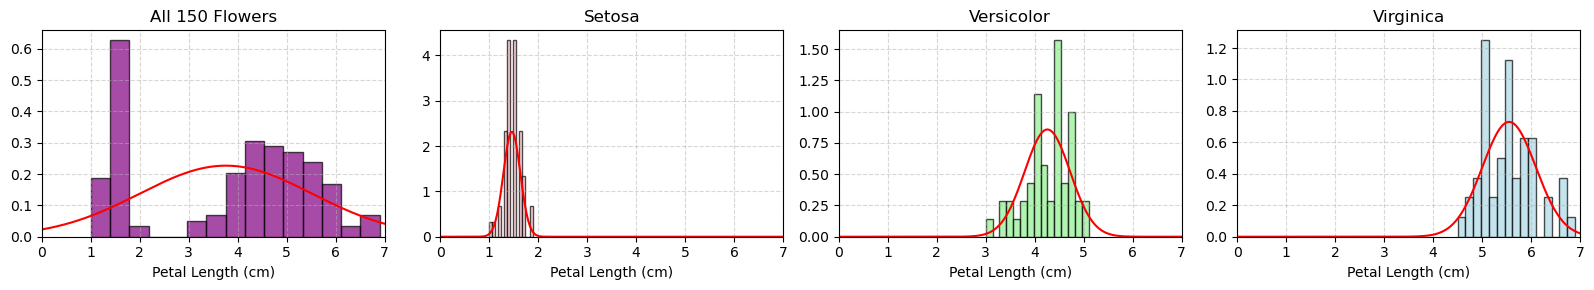

In [ ]:
# compare the four distributions side by side
fig, axes = plt.subplots(1, 4, figsize=(16, 3))

# store the four petal length datasets in a list
datasets = [petal_length, setosa_petal_length,versicolor_petal_length, virginica_petal_length]

# define titles and colors for each subplot
titles = ['All 150 Flowers', 'Setosa', 'Versicolor', 'Virginica']
colors = ['purple', 'pink', 'lightgreen', 'lightblue']

# generate 200 evenly spaced values between 0 and 7 for plotting the normal distribution curves

x = np.linspace(0, 7, 200)

# use zip() to loop through the subplots, datasets, titles and colours together
# https://docs.python.org/3/builtins/functions.html#zip

for ax, data, title, color in zip(axes, datasets, titles, colors):

    ax.hist(data, bins=15, density=True, color=color,
            edgecolor='black', alpha=0.7)

    ax.plot(x, stats.norm.pdf(x, np.mean(data), np.std(data)),
            color='red')

    ax.set_title(title)
    # use the same x-axis range for a consistent comparison

    ax.set_xlim(0, 7)
    ax.set_xlabel('Petal Length (cm)')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### Analysis and Interpretation of Petal Length Distributions

* All 150 Flowers

The mean petal length is 3.76 cm, with a standard deviation of 1.76 cm.

The histogram shows two distinct peaks, which indicates a bimodal distribution. The high standard deviation reflects the large variation in petal lengths.

The normal curve does not closely follow the shape of the histogram. Therefore, a single normal distribution is not a reasonable model for the complete dataset.

* Setosa

The mean petal length is 1.46 cm, with a standard deviation of 0.17 cm.

Setosa has the shortest and most consistent petal lengths. The low standard deviation explains the narrow shape of the normal distribution curve.

Although the histogram is not perfectly symmetrical, a normal distribution appears to be a reasonable approximation.

* Versicolor

The mean petal length is 4.26 cm, with a standard deviation of 0.47 cm.

Versicolor has longer petal lengths and greater variability than Setosa.

The histogram is slightly asymmetrical, but the normal curve reasonably represents the overall distribution.

* Virginica

The mean petal length is 5.55 cm, with a standard deviation of 0.55 cm.

Virginica has the longest petal lengths and the greatest variability among the three individual species.

Although the histogram does not perfectly follow the normal curve, a normal distribution appears to be a reasonable approximation.

* Final Conclusion

The analysis shows clear differences in petal length between the three species.

Setosa has the shortest and most consistent petal lengths, followed by Versicolor and Virginica. While Setosa is clearly separated from the other species, Versicolor and Virginica show some overlap.

A normal distribution is a more reasonable model for the individual species than for the complete dataset, where combining the three species results in a bimodal distribution.



## End